In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from charge_correlator.plot.utils import (get_data, calc_hist, get_rc_and_err, get_rc_and_err_unweighted, get_rc_and_err_new)

In [ ]:
HERWIG_PREFIX= '/nfs/roberts/pi/pi_lbh35/youqi/herwig'
PTHAT_BINS = ['11pthat15', '15pthat20', '20pthat25', '25pthat30', '30pthat35',
              '35pthat40', '40pthat45', '45pthat50', '50pthat1000']
TRUTH_COLS = ['evid', 'xsec', 'pt', 'n', 'parton', 'nch',
              'pt1', 'q1', 'eta1', 'phi1', 'pid1', 'parent1',
              'pt2', 'q2', 'eta2', 'phi2', 'pid2', 'parent2',
              'dr', 'm', 'nparents1', 'nparents2']

EMB_FILE   = '/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root'
COLUMNS   = ['pt', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2',
             'pts', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s', 'nefs']

PT_EDGES   = [20, 25, 30, 40, 60]
PT_CENTERS = [22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 5, 10]

plt.rcParams['font.size'] = 15

In [77]:
def bin_df_in_pt(df):
    return [df[(df.pt > PT_EDGES[i]) & (df.pt < PT_EDGES[i+1])] for i in range(4)]

def get_rc_and_err_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_mc(observables, filename_prefix, pthat_bins):
    dfs = []
    for pthat_bin in pthat_bins:
        df = pd.read_csv(f'{filename_prefix}_{pthat_bin}_rc_truth.txt', names=observables, low_memory=False)
        df['w'] = float(df.iloc[-1]['xsec']) / 200000
        dfs.append(df)
    return pd.concat(dfs)

# Compare truth

In [78]:
# Herwig truth
df_hw = get_mc(TRUTH_COLS, HERWIG_PREFIX, PTHAT_BINS)
df_hw = df_hw.query('pt>20 and abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15').copy()
df_hw.eval('b_ch = q1*q2', inplace=True)
df_hw_pt = bin_df_in_pt(df_hw)

rc_pt_hw, err_pt_hw = get_rc_and_err_arr(df_hw_pt, 'b_ch')

In [79]:
# Pythia6 truth
df_pythia6 = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('b!=0 and b!=-9 and pt>5')
df_pythia6_pt = bin_df_in_pt(df_pythia6)

rc_pythia6, err_pythia6 = get_rc_and_err_arr(df_pythia6_pt, 'b')

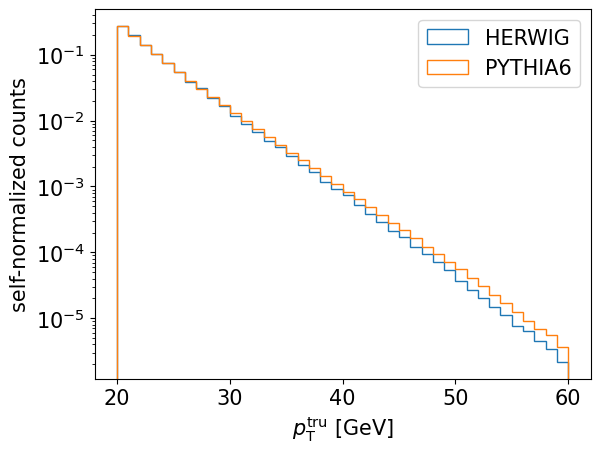

In [40]:
plt.hist(df_hw['pt'], bins=np.arange(20,61), weights=df_hw['w'], density=True, histtype='step', label='HERWIG')
plt.hist(df_pythia6[df_pythia6.pt>20]['pt'], bins=np.arange(20,61), weights=df_pythia6[df_pythia6.pt>20]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.legend()

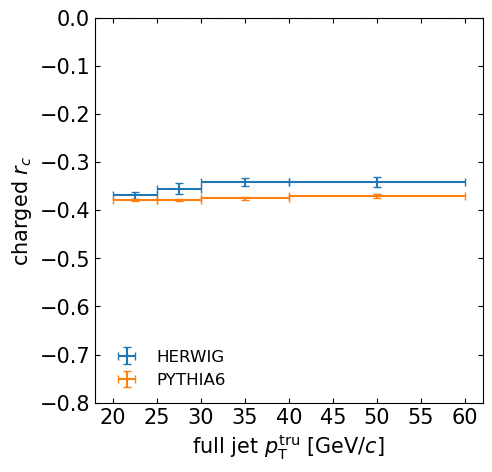

In [81]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, rc_pt_hw, xerr=PT_XERR, yerr=err_pt_hw,
            capsize=3, ls='none', label='HERWIG')
ax.errorbar(PT_CENTERS, rc_pythia6, xerr=PT_XERR, yerr=err_pythia6,
            capsize=3, ls='none', label='PYTHIA6')
ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\rm{T}}^{\rm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$', fontsize=15)
ax.set_ylim(-0.8, 0)
ax.legend(fontsize=12, loc='lower left', frameon=False)
ax.set_xticks(np.arange(20, 65, 5))
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.show()

# Compute reweight factors

In [82]:
RANGE_LOW, RANGE_HIGH, N_BINS = -1.2, 1.2, 2
b_bins = np.arange(RANGE_LOW, RANGE_HIGH + (RANGE_HIGH - RANGE_LOW) / N_BINS,
                   (RANGE_HIGH - RANGE_LOW) / N_BINS)

b_hw_array = []
for df in df_hw_pt:
    y, _, _ = calc_hist(df['b_ch'], bins=b_bins, weights=df['w'], density=True)
    b_hw_array.append(y / sum(y))

b_pythia6_array = []
for df in df_pythia6_pt:
    y, _, _ = calc_hist(df['b'], bins=b_bins, weights=df['w'], density=True)
    b_pythia6_array.append(y / sum(y))

In [83]:
print(b_hw_array)
print(b_pythia6_array)

[array([0.68472381, 0.31527619]), array([0.67759574, 0.32240426]), array([0.67064969, 0.32935031]), array([0.67091156, 0.32908844])]
[array([0.68946251, 0.31053749]), array([0.68974903, 0.31025097]), array([0.68781733, 0.31218267]), array([0.68543662, 0.31456338])]


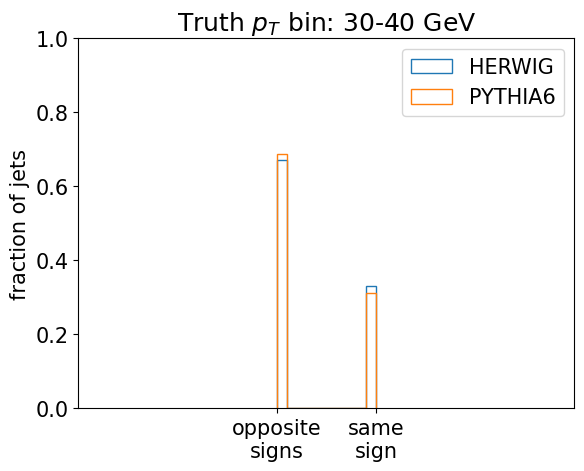

In [50]:
plt.hist([-1, 1], histtype='step', weights=b_hw_array[2], label='HERWIG')
plt.hist([-1, 1], histtype='step', weights=b_pythia6_array[2], label='PYTHIA6')
plt.title('Truth $p_T$ bin: 30-40 GeV')
plt.ylim(0, 1)
plt.xlim(-5, 5)
plt.xticks([-1, 1],['opposite\nsigns', 'same\nsign'])
plt.ylabel('fraction of jets')
plt.legend()

In [84]:
prior_reweight_array = []
for i in range(4):
    num     = b_hw_array[i] / sum(b_hw_array[i])
    denom   = b_pythia6_array[i] / sum(b_pythia6_array[i])
    rw      = num / denom
    prior_reweight_array.append(rw)

prior_reweight_array

[array([0.99312696, 1.01525968]),
 array([0.98238014, 1.03917243]),
 array([0.97504042, 1.05499227]),
 array([0.97880905, 1.04617529])]

# Reweight

In [ ]:
prior_rw = np.array(prior_reweight_array)   # shape (4, 2): prior_rw[i,0]=os weight, prior_rw[i,1]=ss weight
pt_vals = df_pythia6['pt'].values
b_vals  = df_pythia6['b'].values
bin_idx  = np.clip(np.digitize(pt_vals, PT_EDGES) - 1, 0, 3)
df_pythia6 = df_pythia6.copy()
df_pythia6['r'] = np.where(b_vals == -1, prior_rw[bin_idx, 0], prior_rw[bin_idx, 1])

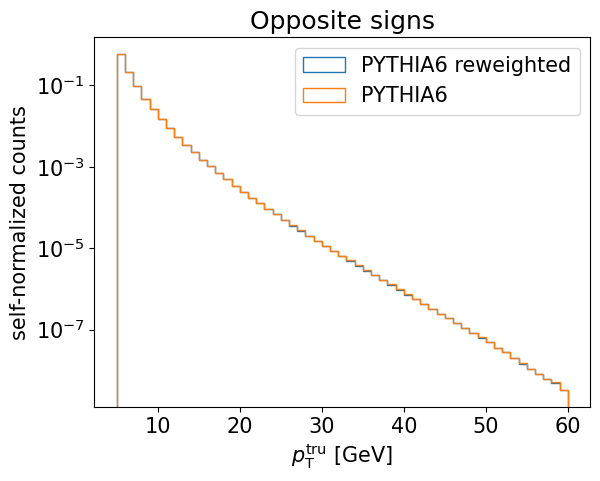

In [86]:
plt.hist(df_pythia6[df_pythia6.b==-1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==-1]['w']*df_pythia6[df_pythia6.b==-1]['r'], density=True, histtype='step', label='PYTHIA6 reweighted')
plt.hist(df_pythia6[df_pythia6.b==-1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==-1]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.title('Opposite signs')
plt.legend()

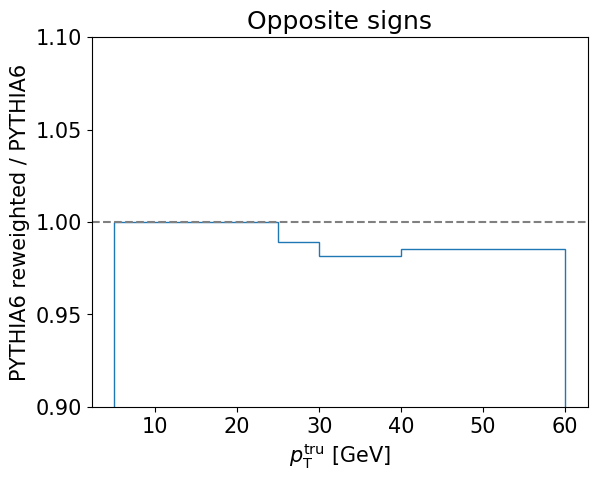

In [87]:
df = df_pythia6[df_pythia6.b == -1]
bins = np.arange(5, 61)

h_rw, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'] * df['r'], density=True
)
h_original, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'], density=True
)

# Leave bins with a zero denominator undefined.
ratio = np.divide(
    h_rw, h_original,
    out=np.full_like(h_rw, np.nan),
    where=h_original != 0,
)

plt.figure()
plt.stairs(ratio, bins)
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel(r'$p_{\mathrm{T}}^{\mathrm{tru}}$ [GeV]')
plt.ylabel('PYTHIA6 reweighted / PYTHIA6')
plt.title('Opposite signs')
plt.ylim(0.9, 1.1)
plt.show()


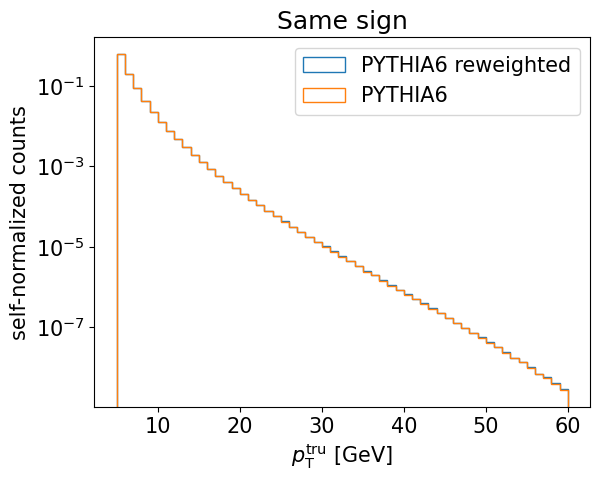

In [88]:
plt.hist(df_pythia6[df_pythia6.b==1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==1]['w']*df_pythia6[df_pythia6.b==1]['r'], density=True, histtype='step', label='PYTHIA6 reweighted')
plt.hist(df_pythia6[df_pythia6.b==1]['pt'], bins=np.arange(5,61), weights=df_pythia6[df_pythia6.b==1]['w'], density=True, histtype='step', label='PYTHIA6')
plt.yscale('log')
plt.xlabel(r'$p_{\rm{T}}^{\rm{tru}}$ [GeV]')
plt.ylabel('self-normalized counts')
plt.title('Same sign')
plt.legend()

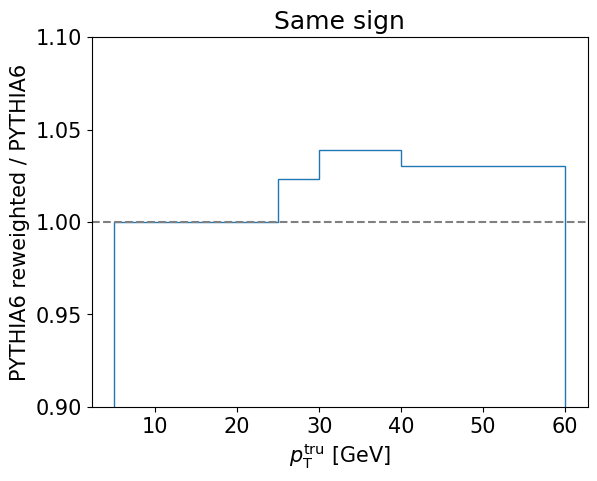

In [89]:
df = df_pythia6[df_pythia6.b == 1]
bins = np.arange(5, 61)

h_rw, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'] * df['r'], density=True
)
h_original, _ = np.histogram(
    df['pt'], bins=bins, weights=df['w'], density=True
)

# Leave bins with a zero denominator undefined.
ratio = np.divide(
    h_rw, h_original,
    out=np.full_like(h_rw, np.nan),
    where=h_original != 0,
)

plt.figure()
plt.stairs(ratio, bins)
plt.axhline(1, color='gray', linestyle='--')
plt.xlabel(r'$p_{\mathrm{T}}^{\mathrm{tru}}$ [GeV]')
plt.ylabel('PYTHIA6 reweighted / PYTHIA6')
plt.title('Same sign')
plt.ylim(0.9, 1.1)
plt.show()


# Save to csv

In [91]:
# Save a CSV with w replaced by w * r and r removed, leaving df_pythia6 unchanged
df_out = df_pythia6.copy()
df_out['w'] = df_out['w'] * df_out['r']
df_out = df_out.drop(columns='r')
df_out.to_csv('rc_reweighted_to_herwig.csv', index=False)

In [92]:
df_out_pt = bin_df_in_pt(df_out)

rc_out, err_out = get_rc_and_err_arr(df_out_pt, 'b')

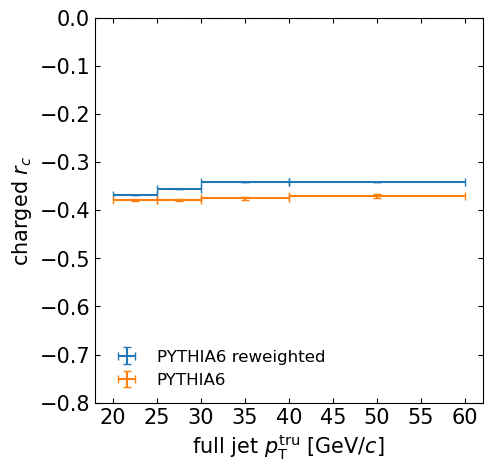

In [93]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(PT_CENTERS, rc_out, xerr=PT_XERR, yerr=err_out,
            capsize=3, ls='none', label='PYTHIA6 reweighted')
ax.errorbar(PT_CENTERS, rc_pythia6, xerr=PT_XERR, yerr=err_pythia6,
            capsize=3, ls='none', label='PYTHIA6')
ax.axhline(0.0, color='grey', linestyle='--')
ax.set_xlabel(r'full jet $p_{\rm{T}}^{\rm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('charged $r_c$', fontsize=15)
ax.set_ylim(-0.8, 0)
ax.legend(fontsize=12, loc='lower left', frameon=False)
ax.set_xticks(np.arange(20, 65, 5))
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
plt.show()